# Daily rolling cointegration strength for transient pairs

This notebook uses the **same transient pairs** selected by `short_window_cointegration_analysis.py`, but replaces discrete 50-day blocks with a rolling test at every daily endpoint.

The previous plots display $-\log_{10}(p)$. Consequently, a value **over** the strength threshold represents a **small raw p-value** and stronger in-window cointegration evidence. With the default threshold of 3, coloured points have `raw p <= 0.001`. Values below the threshold are muted.

This is a descriptive rolling view. A coloured point does not by itself establish forward tradeability.

In [ ]:
%matplotlib inline
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import coint

WINDOW = 42
STEP = 1
TOP_N = 40
STRENGTH_THRESHOLD = 3.0       # -log10(p) >= 3 means raw p <= 0.001
USE_LOG_PRICES = False         # False matches the original block matrices
MAXLAG = 1                     # fixed lag keeps daily rolling results reproducible
AUTOLAG = None

OUTPUT_DIR = Path('cointegration_output/short_regime_analysis')
PAIR_FILE = OUTPUT_DIR / 'transient_pair_metrics.csv'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_P_CUTOFF = 10.0 ** (-STRENGTH_THRESHOLD)
print(f'Colour threshold: strength >= {STRENGTH_THRESHOLD:g} <=> raw p <= {RAW_P_CUTOFF:.6g}')

Colour threshold: strength >= 3 <=> raw p <= 0.001


In [9]:
prices = pd.read_csv('prices.txt', sep=r'\s+')
if not PAIR_FILE.exists():
    raise FileNotFoundError(
        f'{PAIR_FILE} is missing. Run: py short_window_cointegration_analysis.py'
    )

pair_metrics = pd.read_csv(PAIR_FILE)
selected = (
    pair_metrics
    .sort_values(['max_strength', 'n_sig_blocks'], ascending=[False, True])
    .head(TOP_N)
    .reset_index(drop=True)
)

data = np.log(prices) if USE_LOG_PRICES else prices.copy()
end_days = np.arange(WINDOW, len(prices) + 1, STEP)
print(f'{len(prices)} days, {len(selected)} pairs, {len(end_days)} rolling endpoints')
display(selected[['pair', 'n_sig_blocks', 'peak_block', 'max_strength']].head(15))

750 days, 40 pairs, 715 rolling endpoints


,pair,n_sig_blocks,peak_block,max_strength
0,DUCT-MHRM,2,11,6.352724
1,RCRI-NAYO,2,7,5.736573
2,DUCT-EAFC,2,11,5.083661
3,IHOZ-MHRM,2,3,4.863613
4,DIHO-AETS,2,4,4.804010
5,ELLT-HTRK,2,2,4.672093
6,ULXY-BENI,1,5,4.499641
7,ELLT-NGTE,2,2,4.256045
8,ALUT-EELT,1,8,4.179378
9,DIHO-RTTH,1,4,4.160809


In [10]:
# Compute one 50-day Engle-Granger p-value at every daily endpoint.
rolling_p = np.full((len(selected), len(end_days)), np.nan)
warnings.filterwarnings('ignore')

for row_idx, row in selected.iterrows():
    y_all = data[row['ticker_a']].to_numpy(float)
    x_all = data[row['ticker_b']].to_numpy(float)
    for col_idx, end in enumerate(end_days):
        y = y_all[end - WINDOW:end]
        x = x_all[end - WINDOW:end]
        if np.std(y) < 1e-12 or np.std(x) < 1e-12:
            continue
        try:
            rolling_p[row_idx, col_idx] = coint(
                y, x, maxlag=MAXLAG, autolag=AUTOLAG
            )[1]
        except Exception:
            pass
    if (row_idx + 1) % 5 == 0 or row_idx + 1 == len(selected):
        print(f'completed {row_idx + 1}/{len(selected)} pairs')

rolling_strength = -np.log10(np.clip(rolling_p, 1e-16, 1.0))
event_mask = rolling_strength >= STRENGTH_THRESHOLD

pvalue_frame = pd.DataFrame(rolling_p, index=selected['pair'], columns=end_days)
strength_frame = pd.DataFrame(rolling_strength, index=selected['pair'], columns=end_days)
pvalue_frame.to_csv(OUTPUT_DIR / 'rolling_pair_pvalues_daily.csv')
strength_frame.to_csv(OUTPUT_DIR / 'rolling_pair_strength_daily.csv')
print(f'Threshold points: {int(event_mask.sum()):,}')

completed 5/40 pairs
completed 10/40 pairs
completed 15/40 pairs
completed 20/40 pairs
completed 25/40 pairs
completed 30/40 pairs
completed 35/40 pairs
completed 40/40 pairs
Threshold points: 275


## Rolling daily heatmap

Every column is a daily rolling endpoint rather than a non-overlapping block. Grey cells are below the threshold; colour is directly proportional to $-\log_{10}(p)$.

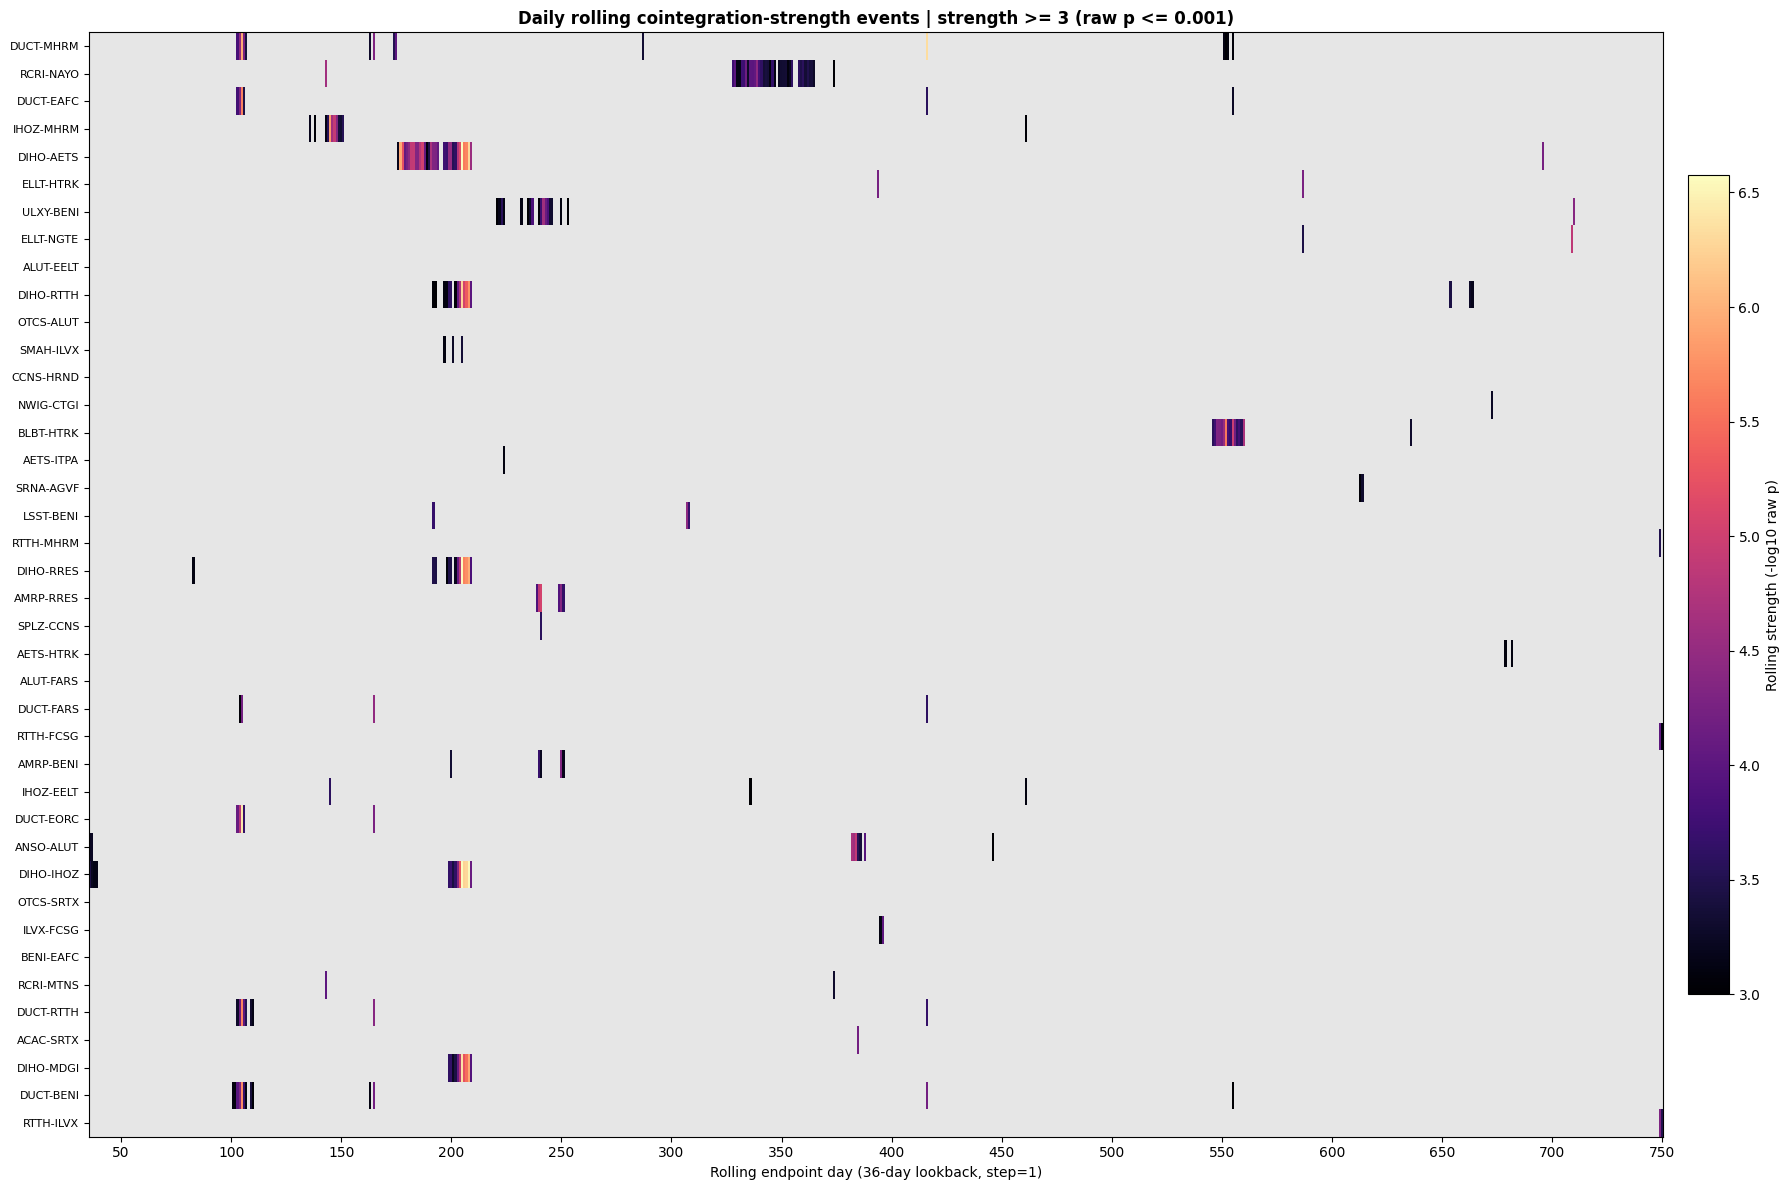

cointegration_output\short_regime_analysis\rolling_cointegration_strength_heatmap.png


In [11]:
masked_strength = np.ma.masked_where(~event_mask, rolling_strength)
cmap = plt.cm.magma.copy()
cmap.set_bad('#e6e6e6')
finite_events = rolling_strength[event_mask]
vmax = max(STRENGTH_THRESHOLD + 1, np.nanpercentile(finite_events, 99))

fig, ax = plt.subplots(figsize=(18, max(10, 0.30 * len(selected))))
im = ax.imshow(
    masked_strength, aspect='auto', interpolation='nearest',
    cmap=cmap, vmin=STRENGTH_THRESHOLD, vmax=vmax,
)
tick_days = np.arange(50, len(prices) + 1, 50)
tick_pos = [int(np.argmin(np.abs(end_days - day))) for day in tick_days]
ax.set_xticks(tick_pos, tick_days)
ax.set_yticks(np.arange(len(selected)), selected['pair'], fontsize=8)
ax.set_xlabel(f'Rolling endpoint day ({WINDOW}-day lookback, step={STEP})')
ax.set_title(
    f'Daily rolling cointegration-strength events | strength >= {STRENGTH_THRESHOLD:g} '
    f'(raw p <= {RAW_P_CUTOFF:.4g})', fontweight='bold'
)
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.015)
cbar.set_label('Rolling strength (-log10 raw p)')
fig.tight_layout()
heatmap_path = OUTPUT_DIR / 'rolling_cointegration_strength_heatmap.png'
fig.savefig(heatmap_path, dpi=170, bbox_inches='tight')
plt.show()
print(heatmap_path)

## Every above-threshold point

This scatter version removes the muted background. Each dot is one pair/day endpoint and its colour encodes the exact strength.

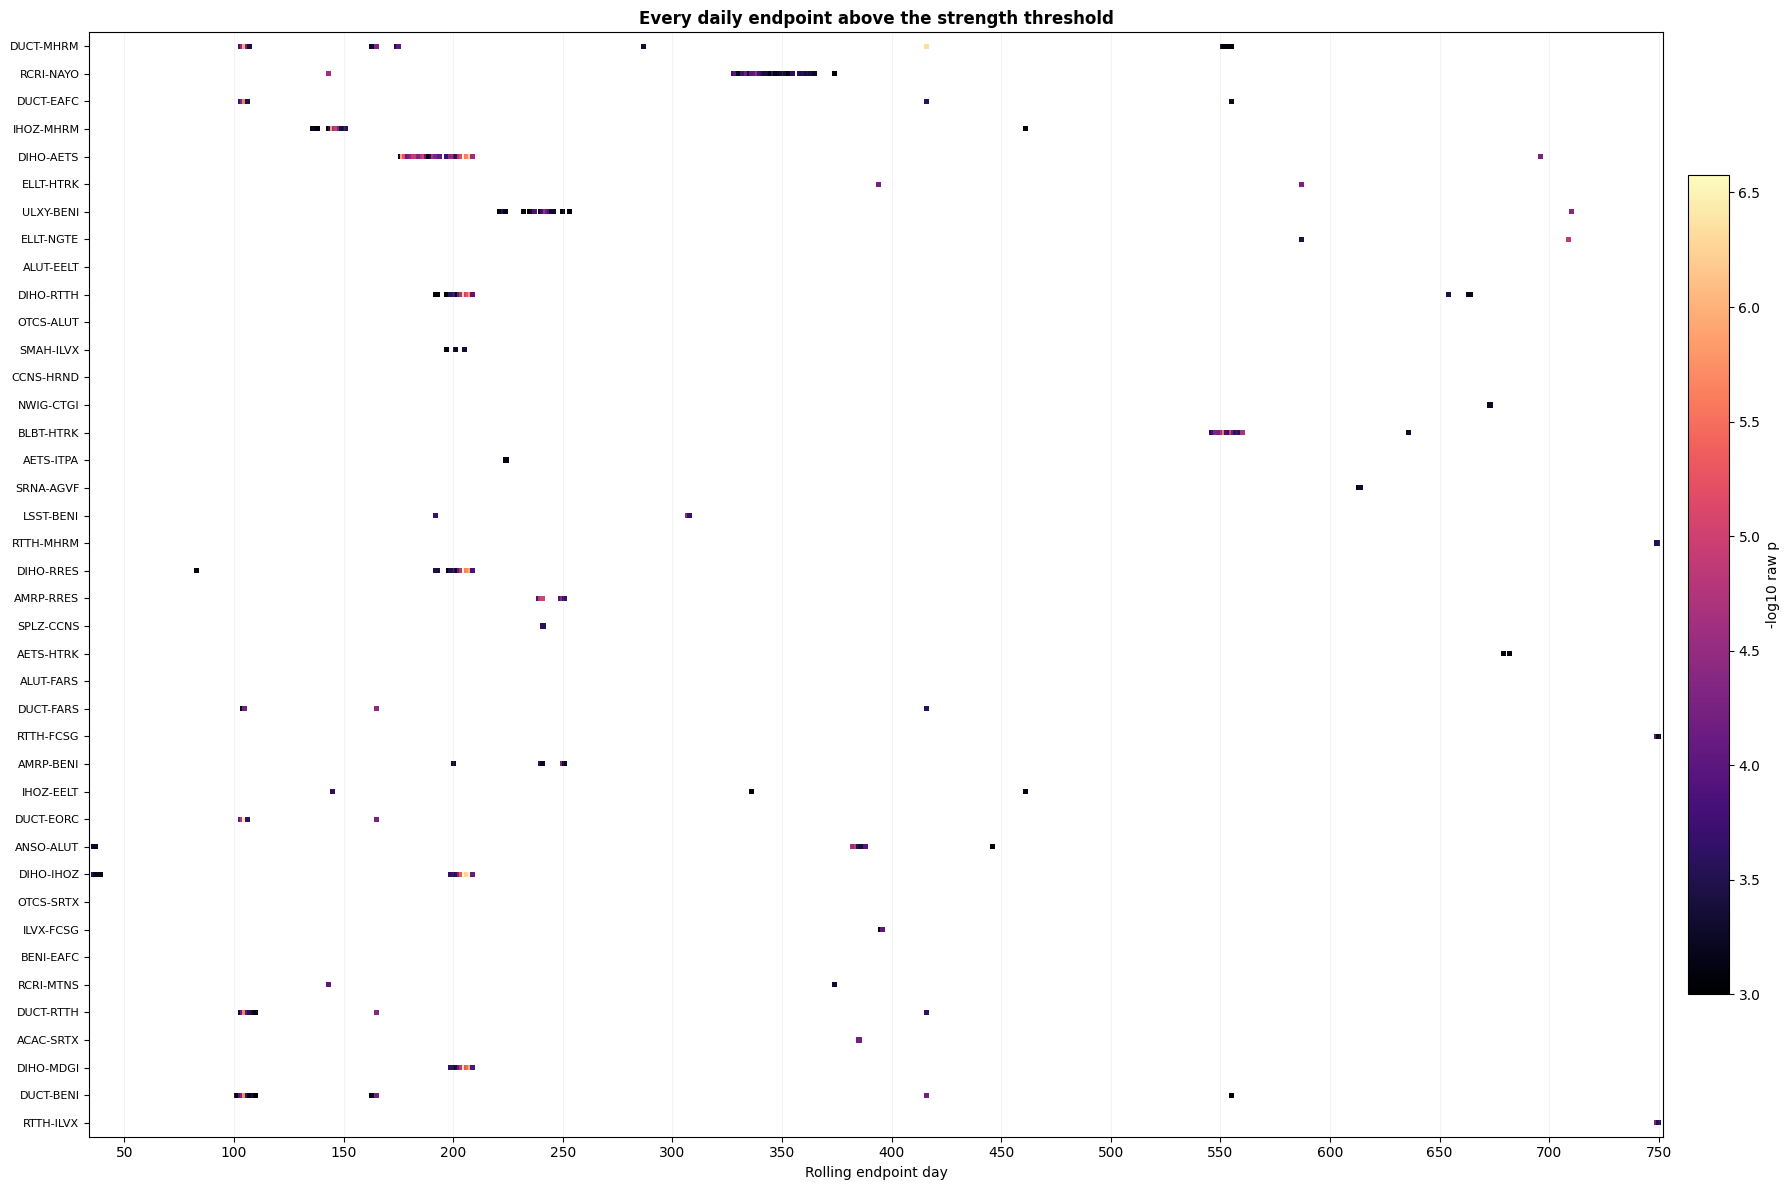

cointegration_output\short_regime_analysis\rolling_cointegration_event_points.png


In [12]:
fig, ax = plt.subplots(figsize=(18, max(10, 0.30 * len(selected))))
for row_idx, pair in enumerate(selected['pair']):
    cols = np.where(event_mask[row_idx])[0]
    if len(cols) == 0:
        continue
    ax.scatter(
        end_days[cols], np.full(len(cols), row_idx),
        c=rolling_strength[row_idx, cols], cmap='magma',
        vmin=STRENGTH_THRESHOLD, vmax=vmax, s=13, marker='s', linewidths=0,
    )
ax.set_yticks(np.arange(len(selected)), selected['pair'], fontsize=8)
ax.set_xticks(tick_days)
ax.set_xlim(WINDOW - 2, len(prices) + 2)
ax.set_ylim(len(selected) - 0.5, -0.5)
ax.set_xlabel('Rolling endpoint day')
ax.set_title('Every daily endpoint above the strength threshold', fontweight='bold')
sm = plt.cm.ScalarMappable(cmap='magma', norm=plt.Normalize(STRENGTH_THRESHOLD, vmax))
fig.colorbar(sm, ax=ax, fraction=0.025, pad=0.015, label='-log10 raw p')
ax.grid(axis='x', alpha=0.15)
fig.tight_layout()
points_plot_path = OUTPUT_DIR / 'rolling_cointegration_event_points.png'
fig.savefig(points_plot_path, dpi=170, bbox_inches='tight')
plt.show()
print(points_plot_path)

## Point and contiguous-run tables

Overlapping rolling windows create runs of adjacent coloured points. The first table stores every point; the second compresses consecutive endpoints into interpretable episodes.

In [13]:
point_rows = []
run_rows = []
for row_idx, pair in enumerate(selected['pair']):
    cols = np.where(event_mask[row_idx])[0]
    for col in cols:
        point_rows.append({
            'pair': pair, 'end_day': int(end_days[col]),
            'raw_p': float(rolling_p[row_idx, col]),
            'strength': float(rolling_strength[row_idx, col]),
        })
    if len(cols) == 0:
        continue
    groups = np.split(cols, np.where(np.diff(cols) > 1)[0] + 1)
    for group in groups:
        peak_col = group[np.argmax(rolling_strength[row_idx, group])]
        run_rows.append({
            'pair': pair,
            'start_day': int(end_days[group[0]]),
            'end_day': int(end_days[group[-1]]),
            'duration_endpoints': int(len(group)),
            'peak_day': int(end_days[peak_col]),
            'peak_strength': float(rolling_strength[row_idx, peak_col]),
            'minimum_raw_p': float(rolling_p[row_idx, peak_col]),
        })

point_table = pd.DataFrame(point_rows).sort_values(['pair', 'end_day'])
run_table = pd.DataFrame(run_rows).sort_values(['peak_strength', 'duration_endpoints'], ascending=False)
point_table.to_csv(OUTPUT_DIR / 'rolling_threshold_points.csv', index=False)
run_table.to_csv(OUTPUT_DIR / 'rolling_threshold_runs.csv', index=False)
print(f'{len(point_table):,} coloured points forming {len(run_table):,} contiguous episodes')
display(run_table.head(25))

275 coloured points forming 93 contiguous episodes


,pair,start_day,end_day,duration_endpoints,peak_day,peak_strength,minimum_raw_p
76,DIHO-IHOZ,199,209,11,205,7.476937,3.334746e-08
53,DIHO-RRES,202,209,8,205,6.703620,1.978699e-07
21,DIHO-AETS,197,209,13,205,6.678289,2.097544e-07
69,DUCT-EORC,103,106,4,105,6.417735,3.821778e-07
85,DIHO-MDGI,199,209,11,205,6.373833,4.228308e-07
5,DUCT-MHRM,416,416,1,416,6.334740,4.626581e-07
36,DIHO-RTTH,202,209,8,205,6.261691,5.474058e-07
0,DUCT-MHRM,103,107,5,105,5.947583,1.128279e-06
20,DIHO-AETS,176,194,19,177,5.945533,1.133619e-06
18,IHOZ-MHRM,143,151,9,145,5.844860,1.429354e-06


## Detailed timelines for the most active pairs

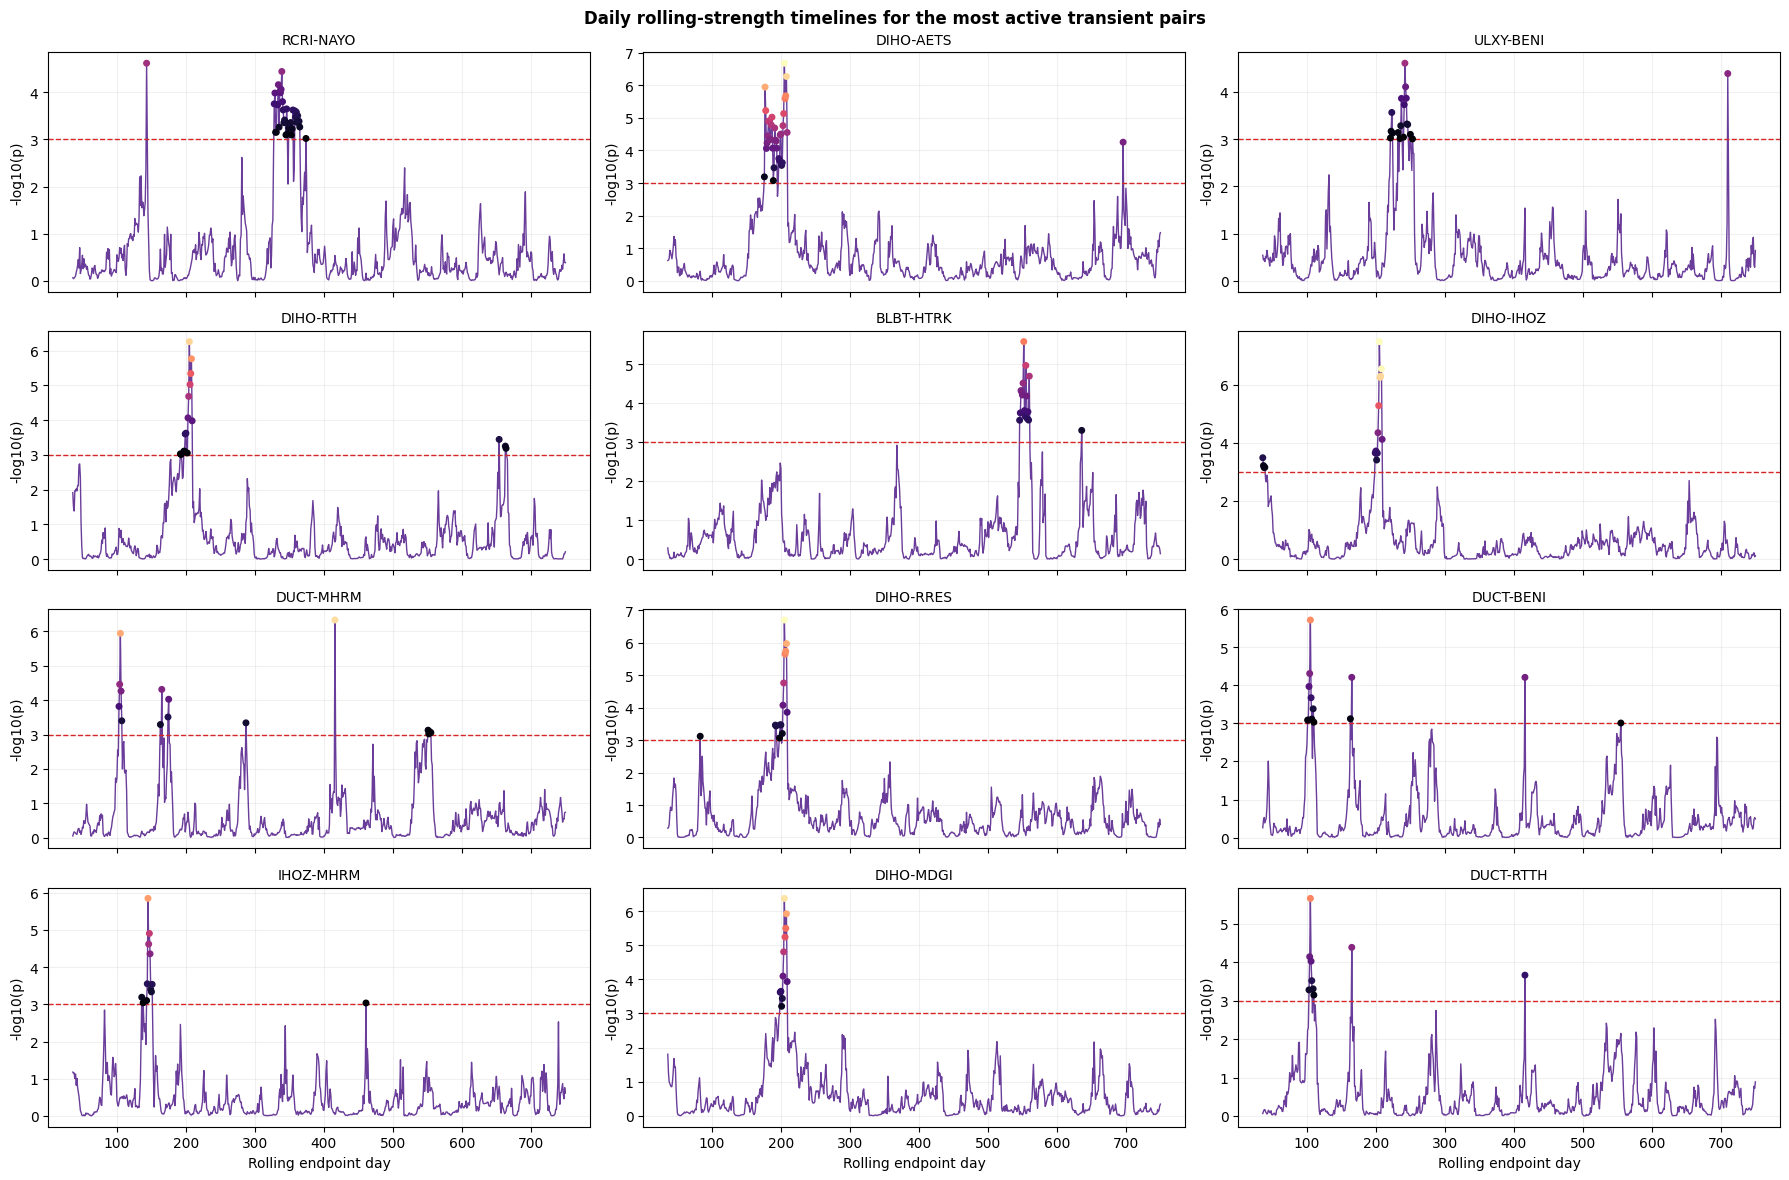

cointegration_output\short_regime_analysis\rolling_cointegration_pair_timelines.png


In [14]:
active_pairs = (
    point_table.groupby('pair')
    .agg(event_points=('end_day', 'size'), peak_strength=('strength', 'max'))
    .sort_values(['event_points', 'peak_strength'], ascending=False)
    .head(12)
    .index
)
fig, axes = plt.subplots(4, 3, figsize=(18, 12), sharex=True)
for ax, pair in zip(axes.flat, active_pairs):
    row_idx = selected.index[selected['pair'] == pair][0]
    values = rolling_strength[row_idx]
    cols = np.where(event_mask[row_idx])[0]
    ax.plot(end_days, values, color='#6a3d9a', lw=1)
    ax.scatter(
        end_days[cols], values[cols], c=values[cols], cmap='magma',
        vmin=STRENGTH_THRESHOLD, vmax=vmax, s=16, zorder=3,
    )
    ax.axhline(STRENGTH_THRESHOLD, color='#d62728', ls='--', lw=1)
    ax.set_title(pair, fontsize=10)
    ax.set_ylabel('-log10(p)')
    ax.grid(alpha=0.18)
for ax in axes[-1]:
    ax.set_xlabel('Rolling endpoint day')
fig.suptitle('Daily rolling-strength timelines for the most active transient pairs', fontweight='bold')
fig.tight_layout()
timeline_path = OUTPUT_DIR / 'rolling_cointegration_pair_timelines.png'
fig.savefig(timeline_path, dpi=170, bbox_inches='tight')
plt.show()
print(timeline_path)